# 🍼 NeoJaundice TSB Estimation — EfficientNet-B7 + MLP Fusion Model (Improved)
**Architecture:** Image preprocessing → EfficientNet-B7 Visual Branch (pretrained) + Clinical MLP Branch → Embedding Fusion → Dual-Head (Regression + Classification)

**Improvements over baseline:**
- ✅ EfficientNet-B7 pretrained backbone (replaces scratch CNN) — higher capacity
- ✅ GELU activations throughout MLP/Fusion layers
- ✅ Weighted CrossEntropyLoss to handle class imbalance
- ✅ Dropout reduced from 0.4 → 0.2
- ✅ Epochs increased to 40 with patience=15
- ✅ Classification loss prioritized (0.3 reg / 0.7 cls)
- ✅ Label smoothing 0.1
- ✅ TSB normalised before MSE loss

**Dataset:** NeoJaundice Dataset (images folder + chd_jaundice.csv)

---

## 📦 Cell 1 — Install Dependencies

In [2]:
# # Install required libraries
# !pip install -q opencv-python-headless scikit-learn matplotlib seaborn tqdm torchinfo
# print('✅ Dependencies installed')

## 📂 Cell 2 — Configure Paths

In [3]:
import os

# ─── CONFIGURE THESE PATHS ───────────────────────────────────────────────────
IMAGES_DIR   =  "/Users/shubhbhateja/College/minor_project/database/images"       # folder with .jpg/.png images
CSV_PATH     = "database/chd_jaundice_published_2.csv" # clinical metadata CSV
# ─────────────────────────────────────────────────────────────────────────────

print('Images dir exists:', os.path.isdir(IMAGES_DIR))
print('CSV exists       :', os.path.isfile(CSV_PATH))
print('Sample images    :', os.listdir(IMAGES_DIR)[:5])

Images dir exists: True
CSV exists       : True
Sample images    : ['0669-1.jpg', '0432-3.jpg', '0477-3.jpg', '1101-1.jpg', '0964-2.jpg']


## 🔍 Cell 3 — Explore CSV & Understand Columns

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(CSV_PATH)
print('Shape:', df.shape)
print('\nColumns:', df.columns.tolist())
display(df.head(5))
print('\nNull counts:')
print(df.isnull().sum())
print('\nBasic stats:')
display(df.describe())

Shape: (2235, 8)

Columns: ['patient_id', 'image_idx', 'gender', 'gestational_age', 'age(day)', 'weight', 'blood(mg/dL)', 'Treatment']


,patient_id,image_idx,gender,gestational_age,age(day),weight,blood(mg/dL),Treatment
0,3,0003-1.jpg,F,40,5.2,3280,3.9,0
1,3,0003-2.jpg,F,40,5.2,3280,3.9,0
2,3,0003-3.jpg,F,40,5.2,3280,3.9,0
3,35,0035-1.jpg,M,39,8.7,3760,12.2,0
4,35,0035-2.jpg,M,39,8.7,3760,12.2,0



Null counts:
patient_id         0
image_idx          0
gender             0
gestational_age    0
age(day)           6
weight             0
blood(mg/dL)       0
Treatment          0
dtype: int64

Basic stats:


,patient_id,gestational_age,age(day),weight,blood(mg/dL),Treatment
count,2235.000000,2235.000000,2229.000000,2235.000000,2235.000000,2235.000000
mean,747.554362,38.293960,6.599192,3158.778523,11.206846,0.417450
std,420.653073,1.807409,5.703538,529.903610,5.213196,0.493249
min,1.000000,30.000000,0.100000,1690.000000,0.000000,0.000000
25%,356.000000,37.000000,2.500000,2800.000000,7.400000,0.000000
50%,794.000000,39.000000,5.000000,3180.000000,11.800000,0.000000
75%,1139.000000,40.000000,9.000000,3500.000000,15.100000,1.000000
max,1351.000000,42.000000,34.000000,5290.000000,25.700000,1.000000


## ⚙️ Cell 4 — Global Configuration
> **Changes:** Dropout 0.4→0.2, Epochs 15→40, Patience 10→15, REG_WEIGHT 0.5→0.3

In [5]:
import torch

# ─── ADJUST THESE TO MATCH YOUR CSV COLUMN NAMES ─────────────────────────────
IMAGE_ID_COL    = 'image_idx'     # column with image filename (with or without extension)
TSB_COL         = 'blood(mg/dL)'  # Total Serum Bilirubin (mg/dL) — regression target
RISK_COL        = 'risk_level'    # risk category: 'Low'/'Medium'/'High' — classification target
CLINICAL_COLS   = ['weight', 'gestational_age', 'age(day)']  # clinical feature columns
# ─────────────────────────────────────────────────────────────────────────────

# Model / training config
import os
os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"  # ✅ add at very top of cell

IMG_SIZE            = 600          # ✅ keep B7 at native size
BATCH_SIZE          = 16            # ✅ small physical batch (fits in VRAM)
ACCUM_STEPS         = 8            # ✅ 4×8 = effective batch of 32
EPOCHS          = 25           # ✅ Increased from 15 → 40
LR              = 1e-3
BACKBONE_LR     = 1e-4         # ✅ Lower LR for pretrained backbone (fine-tuning)
WEIGHT_DECAY    = 1e-4
DROPOUT         = 0.2          # ✅ Reduced from 0.4 → 0.2
N_FOLDS         = 5
PATIENCE        = 15           # ✅ Increased from 10 → 15
REG_WEIGHT      = 0.3          # ✅ Changed from 0.5 → 0.3 (prioritise classification)
LABEL_SMOOTHING = 0.1          # ✅ New: label smoothing
RISK_CLASSES    = ['Low', 'Medium', 'High']
NUM_CLASSES     = len(RISK_CLASSES)
SEED            = 42

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

torch.manual_seed(SEED)
np.random.seed(SEED)

ModuleNotFoundError: No module named 'torch'

## 🎨 Cell 5 — Image Preprocessing Pipeline (Color Calibration + Skin Segmentation → 2D ROI)

Total images found: 2235
Preprocessed shape: (600, 600, 3), min=0.000, max=0.533


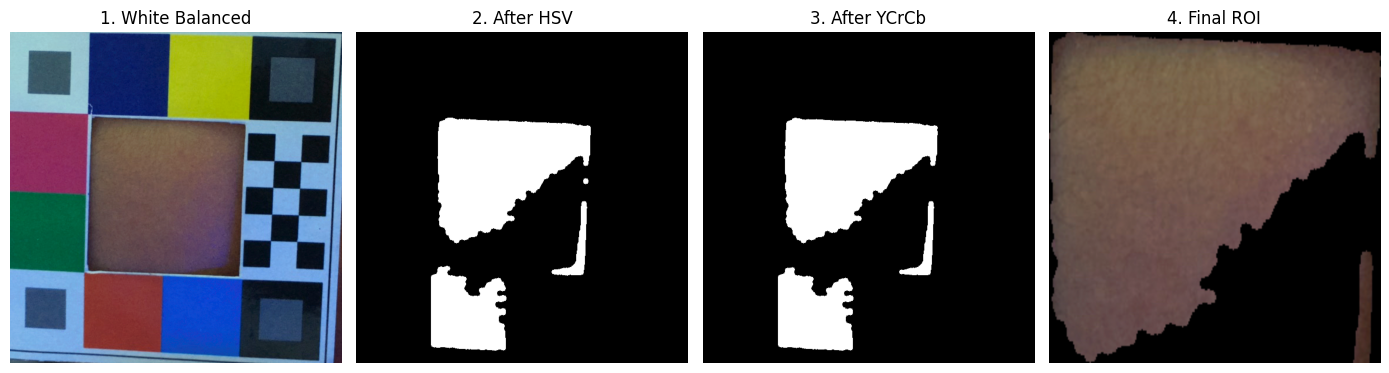

In [ ]:
import cv2
import numpy as np
from pathlib import Path

def detect_hsv_card(image_bgr):
    """
    Detect HSV colour-reference card region.
    Returns a mask for calibration purposes.
    Looks for large rectangular high-saturation region in the periphery.
    """
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, (0, 150, 50), (180, 255, 255))
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    return mask


def lab_white_balance(image_bgr):
    """Grey-world LAB white balancing."""
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    avg_a = np.mean(lab[:, :, 1])
    avg_b = np.mean(lab[:, :, 2])
    lab[:, :, 1] -= (avg_a - 128) * (lab[:, :, 0] / 255.0) * 1.1
    lab[:, :, 2] -= (avg_b - 128) * (lab[:, :, 0] / 255.0) * 1.1
    lab = np.clip(lab, 0, 255).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)


# ── SEQUENTIAL STAGE 1: HSV Skin Segmentation ────────────────────────────────
def segment_skin_hsv(image_bgr):
    """
    Stage 1 — HSV-based skin segmentation.
    Detects warm/skin-toned hues using HSV colour space.
    Returns skin-masked image and binary mask.
    """
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    mask_hsv = cv2.inRange(hsv, (0, 15, 50), (25, 170, 255))

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    mask_hsv = cv2.morphologyEx(mask_hsv, cv2.MORPH_CLOSE, kernel)
    mask_hsv = cv2.morphologyEx(mask_hsv, cv2.MORPH_OPEN,  kernel)

    skin_hsv = cv2.bitwise_and(image_bgr, image_bgr, mask=mask_hsv)
    return skin_hsv, mask_hsv


# ── SEQUENTIAL STAGE 2: YCrCb Refinement ─────────────────────────────────────
def segment_skin_ycrcb(image_bgr, mask_hsv):
    """
    Stage 2 — YCrCb refinement applied on top of HSV result.
    Only pixels that survived Stage 1 (HSV) are kept here.
    Returns further-refined skin image and combined mask.
    """
    ycr = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2YCrCb)
    mask_ycr = cv2.inRange(ycr, (0, 135, 85), (255, 180, 135))

    # Sequential refinement: intersect with previous HSV mask
    mask_combined = cv2.bitwise_and(mask_hsv, mask_ycr)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    mask_combined = cv2.morphologyEx(mask_combined, cv2.MORPH_CLOSE, kernel)
    mask_combined = cv2.morphologyEx(mask_combined, cv2.MORPH_OPEN,  kernel)

    skin_refined = cv2.bitwise_and(image_bgr, image_bgr, mask=mask_combined)
    return skin_refined, mask_combined


# ── SEQUENTIAL STAGE 3: ROI Extraction ───────────────────────────────────────
def extract_roi_sequential(skin_img, mask, target_size):
    """
    Stage 3 — ROI extraction on the sequentially refined skin mask.
    Finds largest contour → crops bounding box → resizes to target_size.
    Falls back to centre crop if no contour found.
    """
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        c = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(c)
        roi = skin_img[y:y+h, x:x+w]
    else:
        # Centre crop fallback
        h, w = skin_img.shape[:2]
        s = min(h, w)
        roi = skin_img[(h-s)//2:(h+s)//2, (w-s)//2:(w+s)//2]

    roi = cv2.resize(roi, (target_size, target_size))
    return roi


# ── FULL SEQUENTIAL PIPELINE ──────────────────────────────────────────────────
def preprocess_image(img_path, target_size=IMG_SIZE):
    """
    Sequential pipeline:
      1. Load image
      2. LAB white balance
      3. Stage 1 — HSV skin segmentation
      4. Stage 2 — YCrCb refinement (on HSV result)
      5. Stage 3 — ROI crop & resize
      6. Return float32 RGB array in [0, 1]
    """
    img = cv2.imread(str(img_path))
    if img is None:
        return np.zeros((target_size, target_size, 3), dtype=np.float32)

    # Step 2: Colour correction
    img = lab_white_balance(img)

    # Step 3: HSV stage
    skin_hsv, mask_hsv = segment_skin_hsv(img)

    # Step 4: YCrCb stage (refines HSV output)
    skin_refined, mask_final = segment_skin_ycrcb(img, mask_hsv)

    # Step 5: ROI extraction on final refined mask
    if mask_final.sum() < 500:
        roi = cv2.resize(img, (target_size, target_size))   # fallback
    else:
        roi = extract_roi_sequential(skin_refined, mask_final, target_size)

    roi = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
    return roi.astype(np.float32) / 255.0


# ── Sanity Check ──────────────────────────────────────────────────────────────
sample_files = list(Path(IMAGES_DIR).glob('*'))
sample_files = [f for f in sample_files if f.suffix.lower() in ('.jpg', '.jpeg', '.png')]
print(f'Total images found: {len(sample_files)}')

if sample_files:
    test_img = preprocess_image(sample_files[0])
    print(f'Preprocessed shape: {test_img.shape}, min={test_img.min():.3f}, max={test_img.max():.3f}')

    # Optional: visualize each sequential stage for debugging
    raw = cv2.imread(str(sample_files[0]))
    raw = lab_white_balance(raw)
    _, mask_hsv   = segment_skin_hsv(raw)
    _, mask_final = segment_skin_ycrcb(raw, mask_hsv)

    plt.figure(figsize=(14, 4))
    for i, (img, title) in enumerate([
        (raw[..., ::-1],    "1. White Balanced"),
        (mask_hsv,          "2. After HSV"),
        (mask_final,        "3. After YCrCb"),
        (test_img,          "4. Final ROI"),
    ]):
        plt.subplot(1, 4, i+1)
        plt.imshow(img, cmap='gray' if img.ndim == 2 else None)
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## 🗂️ Cell 6 — Data Preparation & Label Encoding

In [ ]:
# Create the 'risk_level' column by binning the Total Serum Bilirubin values
def assign_risk(tsb_value):
    if tsb_value < 7.0:
        return 'Low'
    elif tsb_value <= 15.0:
        return 'Medium'
    else:
        return 'High'

df['risk_level'] = df['blood(mg/dL)'].apply(assign_risk)

print("Created risk_level column!")
print(df['risk_level'].value_counts())

Created risk_level column!
risk_level
Medium    1149
High       588
Low        498
Name: count, dtype: int64


Clean rows: 2229
Missing image files: 0
Rows with valid images: 2229
TSB mean=11.21, std=5.21  →  tsb_norm range: [-2.15, 2.78]
Risk class mapping: {np.str_('Low'): np.int64(0), np.str_('Medium'): np.int64(1), np.str_('High'): np.int64(2)}

Class weights (Low/Medium/High): [1.501 0.647 1.27 ]


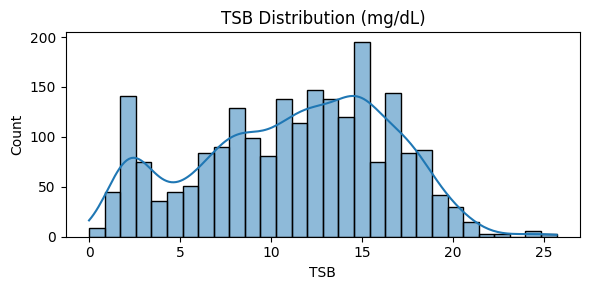


Risk class distribution:
risk_level
Medium    1149
High       585
Low        495
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from pathlib import Path

def find_image_path(img_id, images_dir):
    """Resolve image filename with or without extension."""
    images_dir = Path(images_dir)
    for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']:
        p = images_dir / f'{img_id}{ext}'
        if p.exists():
            return p
        p2 = images_dir / str(img_id)
        if p2.exists():
            return p2
    return None

# ─── Drop rows with missing targets ──────────────────────────────────────────
df = df.dropna(subset=[IMAGE_ID_COL, TSB_COL, RISK_COL] + CLINICAL_COLS).reset_index(drop=True)
print(f'Clean rows: {len(df)}')

# ─── Resolve image paths ──────────────────────────────────────────────────────
df['img_path'] = df[IMAGE_ID_COL].apply(lambda x: find_image_path(x, IMAGES_DIR))
missing = df['img_path'].isna().sum()
print(f'Missing image files: {missing}')
df = df[df['img_path'].notna()].reset_index(drop=True)
print(f'Rows with valid images: {len(df)}')

# ─── Normalise clinical features ─────────────────────────────────────────────
scaler = MinMaxScaler()
df[CLINICAL_COLS] = scaler.fit_transform(df[CLINICAL_COLS].values.astype(np.float32))

# ─── Normalise TSB for regression loss ───────────────────────────────────────
# ✅ NEW: Normalise TSB so MSE is on the same scale as CrossEntropy
tsb_mean = df[TSB_COL].mean()
tsb_std  = df[TSB_COL].std()
df['tsb_norm'] = (df[TSB_COL] - tsb_mean) / tsb_std
print(f'TSB mean={tsb_mean:.2f}, std={tsb_std:.2f}  →  tsb_norm range: [{df["tsb_norm"].min():.2f}, {df["tsb_norm"].max():.2f}]')

# ─── Encode risk labels ───────────────────────────────────────────────────────
le = LabelEncoder()
le.classes_ = np.array(RISK_CLASSES)
df['risk_encoded'] = le.transform(df[RISK_COL].str.strip())
print('Risk class mapping:', dict(zip(le.classes_, le.transform(le.classes_))))

# ─── ✅ Compute class weights for imbalance handling ──────────────────────────
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1, 2]),
    y=df['risk_encoded'].values
)
CLASS_WEIGHTS_TENSOR = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
print(f'\nClass weights (Low/Medium/High): {class_weights.round(3)}')

# ─── TSB distribution ─────────────────────────────────────────────────────────
plt.figure(figsize=(6, 3))
sns.histplot(df[TSB_COL], bins=30, kde=True)
plt.title('TSB Distribution (mg/dL)')
plt.xlabel('TSB')
plt.tight_layout()
plt.show()

print('\nRisk class distribution:')
print(df[RISK_COL].value_counts())

## 🔥 Cell 7 — PyTorch Dataset & Augmentation

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

# ─── Augmentation transforms ──────────────────────────────────────────────────
train_transform = T.Compose([
    T.ToPILImage(),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.2),
    T.RandomRotation(degrees=15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std =[0.229, 0.224, 0.225]),
])

val_transform = T.Compose([
    T.ToPILImage(),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std =[0.229, 0.224, 0.225]),
])


class JaundiceDataset(Dataset):
    def __init__(self, dataframe, transform=None, img_size=IMG_SIZE):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform
        self.img_size  = img_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # ── Image ──────────────────────────────────────────────────────────────
        img = preprocess_image(row['img_path'], self.img_size)  # H×W×3, float32 [0,1]
        img = (img * 255).astype(np.uint8)                       # back to uint8 for transforms
        if self.transform:
            img = self.transform(img)                             # → C×H×W tensor
        else:
            img = torch.from_numpy(img.transpose(2, 0, 1)).float() / 255.0

        # ── Clinical features ──────────────────────────────────────────────────
        clinical = torch.tensor(row[CLINICAL_COLS].values.astype(np.float32))

        # ── Targets ────────────────────────────────────────────────────────────
        # ✅ Use normalised TSB for training stability
        tsb_norm = torch.tensor(float(row['tsb_norm']),       dtype=torch.float32)
        tsb_raw  = torch.tensor(float(row[TSB_COL]),          dtype=torch.float32)
        risk     = torch.tensor(int(row['risk_encoded']),     dtype=torch.long)

        return img, clinical, tsb_norm, tsb_raw, risk


# ─── Quick shape test ─────────────────────────────────────────────────────────
dummy_ds = JaundiceDataset(df.head(4), transform=val_transform)
img, clin, tsb_norm, tsb_raw, risk = dummy_ds[0]
print(f'Image tensor   : {img.shape}')
print(f'Clinical       : {clin.shape}')
print(f'TSB (norm)     : {tsb_norm:.4f}')
print(f'TSB (raw mg/dL): {tsb_raw:.4f}')
print(f'Risk           : {risk}')

Image tensor   : torch.Size([3, 600, 600])
Clinical       : torch.Size([3])
TSB (norm)     : -1.4044
TSB (raw mg/dL): 3.9000
Risk           : 0


## 🧠 Cell 8 — Model Architecture
> **Changes:**
> - ✅ EfficientNet-B7 pretrained backbone replaces scratch 2D CNN (2560-dim features)
> - ✅ GELU activations in all MLP / Fusion layers
> - ✅ Dropout reduced to 0.2

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torchinfo import summary


# ──────────────────────────────────────────────────────────────────────────────
# ✅ Visual Branch — EfficientNet-B7 Pretrained Backbone
# ──────────────────────────────────────────────────────────────────────────────
class VisualBranchEfficientNet(nn.Module):
    """
    Visual Branch using EfficientNet-B7 pretrained on ImageNet.
    The backbone extracts rich visual features (2560-dim).
    A small projection head maps it to embedding_dim with GELU activation.

    """
    def __init__(self, embedding_dim=256, dropout=DROPOUT):
        super().__init__()

        # Load pretrained EfficientNet-B7
        backbone = models.efficientnet_b7(weights=models.EfficientNet_B7_Weights.IMAGENET1K_V1)

        # Remove the original classifier head — keep only the feature extractor
        # ✅ EfficientNet-B7 outputs 2560-dim features after global pooling
        self.backbone = nn.Sequential(*list(backbone.children())[:-1])  # removes classifier
        self.pool     = nn.AdaptiveAvgPool2d((1, 1))

        # ✅ Projection head with GELU
        self.projection = nn.Sequential(
            nn.Flatten(),
            nn.Linear(2560, embedding_dim),  # ✅ B7 outputs 2560-dim
            nn.BatchNorm1d(embedding_dim),
            nn.GELU(),                          # ✅ GELU instead of ReLU
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = self.backbone(x)   # (B, 2560, H', W')
        x = self.pool(x)       # (B, 2560, 1, 1)
        x = self.projection(x) # (B, embedding_dim)
        return x


# ──────────────────────────────────────────────────────────────────────────────
# ✅ MLP Clinical Branch — GELU activations
# ──────────────────────────────────────────────────────────────────────────────
class ClinicalBranchMLP(nn.Module):
    """
    Clinical Branch: normalised clinical parameters → MLP → clinical_embedding
    ✅ Uses GELU activation instead of ReLU
    """
    def __init__(self, input_dim, embedding_dim=64, dropout=DROPOUT):
        super().__init__()
        self.net = nn.Sequential(
            # Layer 1
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),                          # ✅ GELU
            nn.Dropout(dropout),
            # Layer 2
            nn.Linear(128, embedding_dim),
            nn.BatchNorm1d(embedding_dim),
            nn.GELU(),                          # ✅ GELU
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)   # shape: (B, embedding_dim)


# ──────────────────────────────────────────────────────────────────────────────
# ✅ Fusion Model — Dual Head with GELU
# ──────────────────────────────────────────────────────────────────────────────
class NeoJaundiceFusionModel(nn.Module):
    """
    Full architecture:
      VisualBranchEfficientNet + ClinicalBranchMLP
      → Concatenate embeddings
      → Shared FC + Dropout (GELU)
      → Regression Head (TSB normalised)
      → Classification Head (Low / Medium / High)
    """
    def __init__(self,
                 clinical_input_dim,
                 visual_emb_dim   = 256,
                 clinical_emb_dim = 64,
                 num_classes      = NUM_CLASSES,
                 dropout          = DROPOUT):
        super().__init__()

        self.visual_branch   = VisualBranchEfficientNet(embedding_dim=visual_emb_dim, dropout=dropout)
        self.clinical_branch = ClinicalBranchMLP(input_dim=clinical_input_dim,
                                                  embedding_dim=clinical_emb_dim, dropout=dropout)

        fused_dim = visual_emb_dim + clinical_emb_dim

        # ✅ Shared Fusion FC with GELU ─────────────────────────────────────────
        self.fusion = nn.Sequential(
            nn.Linear(fused_dim, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),                          # ✅ GELU
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),                          # ✅ GELU
            nn.Dropout(dropout),
        )

        # ── Regression Head (predicts normalised TSB) ──────────────────────────
        self.regression_head     = nn.Linear(128, 1)

        # ── Classification Head ────────────────────────────────────────────────
        self.classification_head = nn.Linear(128, num_classes)

    def forward(self, img, clinical):
        vis_emb  = self.visual_branch(img)        # (B, visual_emb_dim)
        clin_emb = self.clinical_branch(clinical)  # (B, clinical_emb_dim)

        fused    = torch.cat([vis_emb, clin_emb], dim=1)  # (B, fused_dim)
        shared   = self.fusion(fused)                     # (B, 128)

        tsb_pred  = self.regression_head(shared).squeeze(1)    # (B,)
        risk_pred = self.classification_head(shared)            # (B, num_classes)

        return tsb_pred, risk_pred


# ─── Instantiate & inspect ────────────────────────────────────────────────────
model = NeoJaundiceFusionModel(clinical_input_dim=len(CLINICAL_COLS)).to(DEVICE)

print(model)
print('\n--- Model Summary ---')
summary(model,
        input_data=[torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE),
                    torch.randn(2, len(CLINICAL_COLS)).to(DEVICE)],
        verbose=1)

Downloading: "https://download.pytorch.org/models/efficientnet_b7_lukemelas-c5b4e57e.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b7_lukemelas-c5b4e57e.pth


100%|██████████| 255M/255M [00:01<00:00, 215MB/s] 


NeoJaundiceFusionModel(
  (visual_branch): VisualBranchEfficientNet(
    (backbone): Sequential(
      (0): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): SiLU(inplace=True)
        )
        (1): Sequential(
          (0): MBConv(
            (block): Sequential(
              (0): Conv2dNormActivation(
                (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
                (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
                (2): SiLU(inplace=True)
              )
              (1): SqueezeExcitation(
                (avgpool): AdaptiveAvgPool2d(output_size=1)
                (fc1): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1))
                (fc2): Conv2d(16, 64, kernel_size=(1

Layer (type:depth-idx)                                            Output Shape              Param #
NeoJaundiceFusionModel                                            [2]                       --
├─VisualBranchEfficientNet: 1-1                                   [2, 256]                  --
│    └─Sequential: 2-1                                            [2, 2560, 1, 1]           --
│    │    └─Sequential: 3-1                                       [2, 2560, 19, 19]         63,786,960
│    │    └─AdaptiveAvgPool2d: 3-2                                [2, 2560, 1, 1]           --
│    └─AdaptiveAvgPool2d: 2-2                                     [2, 2560, 1, 1]           --
│    └─Sequential: 2-3                                            [2, 256]                  --
│    │    └─Flatten: 3-3                                          [2, 2560]                 --
│    │    └─Linear: 3-4                                           [2, 256]                  655,616
│    │    └─BatchNorm1d: 3-5    

## 🏋️ Cell 9 — Training & Validation Functions
> **Changes:**
> - ✅ Separate learning rates for backbone vs head (differential LR)
> - ✅ REG_WEIGHT=0.3 (was 0.5) — prioritise classification
> - ✅ Weighted CrossEntropyLoss + label smoothing

In [ ]:
import torch.optim as optim
from tqdm.notebook import tqdm


class EarlyStopping:
    def __init__(self, patience=PATIENCE, min_delta=1e-4):
        self.patience   = patience
        self.min_delta  = min_delta
        self.best_score = None
        self.counter    = 0
        self.best_state = None
        self.stopped    = False

    def step(self, val_loss, model):
        score = -val_loss
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score = score
            self.counter    = 0
            self.best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stopped = True

    def restore_best(self, model):
        if self.best_state:
            model.load_state_dict(self.best_state)


def train_one_epoch(model, loader, optimizer, reg_criterion, cls_criterion, reg_weight=REG_WEIGHT):
    model.train()
    total_loss = total_reg = total_cls = 0
    optimizer.zero_grad()  # ✅ moved outside the loop

    for step, (imgs, clinical, tsb_norm, tsb_raw, risk) in enumerate(tqdm(loader, leave=False, desc='Train')):
        imgs, clinical = imgs.to(DEVICE), clinical.to(DEVICE)
        tsb_norm, risk = tsb_norm.to(DEVICE), risk.to(DEVICE)

        # ✅ Forward pass
        tsb_pred, risk_pred = model(imgs, clinical)

        loss_reg = reg_criterion(tsb_pred, tsb_norm)
        loss_cls = cls_criterion(risk_pred, risk)
        loss     = reg_weight * loss_reg + (1 - reg_weight) * loss_cls

        # ✅ Scale loss by accum steps before backward
        loss = loss / ACCUM_STEPS
        loss.backward()

        total_loss += loss.item() * ACCUM_STEPS  # unscale for logging
        total_reg  += loss_reg.item()
        total_cls  += loss_cls.item()

        # ✅ Only update weights every ACCUM_STEPS batches
        if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(loader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()

            # ✅ Free unused cache after each real update
            torch.cuda.empty_cache()

    n = len(loader)
    return total_loss/n, total_reg/n, total_cls/n

@torch.no_grad()
def validate(model, loader, reg_criterion, cls_criterion, reg_weight=REG_WEIGHT):
    model.eval()
    total_loss = total_reg = total_cls = 0
    all_tsb_true, all_tsb_pred = [], []
    all_risk_true, all_risk_pred = [], []

    for imgs, clinical, tsb_norm, tsb_raw, risk in tqdm(loader, leave=False, desc='Val'):
        imgs, clinical = imgs.to(DEVICE), clinical.to(DEVICE)
        tsb_norm_dev   = tsb_norm.to(DEVICE)
        risk_dev       = risk.to(DEVICE)

        tsb_pred, risk_pred = model(imgs, clinical)

        loss_reg = reg_criterion(tsb_pred, tsb_norm_dev)
        loss_cls = cls_criterion(risk_pred, risk_dev)
        loss     = reg_weight * loss_reg + (1 - reg_weight) * loss_cls

        total_loss += loss.item()
        total_reg  += loss_reg.item()
        total_cls  += loss_cls.item()

        # ✅ De-normalise TSB predictions back to mg/dL for interpretable metrics
        tsb_pred_denorm = tsb_pred.cpu().numpy() * tsb_std + tsb_mean

        all_tsb_true.extend(tsb_raw.numpy())
        all_tsb_pred.extend(tsb_pred_denorm)
        all_risk_true.extend(risk.numpy())
        all_risk_pred.extend(risk_pred.argmax(dim=1).cpu().numpy())

    n = len(loader)
    return (total_loss/n, total_reg/n, total_cls/n,
            np.array(all_tsb_true), np.array(all_tsb_pred),
            np.array(all_risk_true), np.array(all_risk_pred))


print('✅ Training functions defined')

✅ Training functions defined


## 🔄 Cell 10 — Stratified K-Fold Cross-Validation Training
> **Changes:**
> - ✅ Differential learning rates: backbone uses BACKBONE_LR=1e-4, head uses LR=1e-3
> - ✅ Weighted CrossEntropyLoss with label smoothing
> - ✅ 40 epochs, patience=15

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score, r2_score)


def compute_metrics(tsb_true, tsb_pred, risk_true, risk_pred):
    rmse = np.sqrt(np.mean((tsb_true - tsb_pred)**2))
    r2   = r2_score(tsb_true, tsb_pred)
    acc  = accuracy_score(risk_true, risk_pred)
    prec = precision_score(risk_true, risk_pred, average='weighted', zero_division=0)
    rec  = recall_score(risk_true,    risk_pred, average='weighted', zero_division=0)
    f1   = f1_score(risk_true,        risk_pred, average='weighted', zero_division=0)
    return dict(RMSE=rmse, R2=r2, Accuracy=acc, Precision=prec, Recall=rec, F1=f1)


skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

fold_metrics     = []
all_histories    = []
best_model_state = None
best_val_loss    = float('inf')

for fold, (train_idx, val_idx) in enumerate(skf.split(df, df['risk_encoded'])):
    print(f'\n{"="*60}')
    print(f'FOLD {fold+1} / {N_FOLDS}   |   Train: {len(train_idx)}  Val: {len(val_idx)}')
    print('='*60)

    # ── Datasets ──────────────────────────────────────────────────────────────
    train_ds = JaundiceDataset(df.iloc[train_idx], transform=train_transform)
    val_ds   = JaundiceDataset(df.iloc[val_idx],   transform=val_transform)
    train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
    val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

    # ── Model ─────────────────────────────────────────────────────────────────
    import gc
    torch.cuda.empty_cache()
    gc.collect()
    model = NeoJaundiceFusionModel(clinical_input_dim=len(CLINICAL_COLS)).to(DEVICE)

    # ✅ Differential learning rates: backbone (fine-tuning) vs head (full training)
    backbone_params = list(model.visual_branch.backbone.parameters())
    head_params     = ([p for p in model.visual_branch.projection.parameters()] +
                       list(model.clinical_branch.parameters()) +
                       list(model.fusion.parameters()) +
                       list(model.regression_head.parameters()) +
                       list(model.classification_head.parameters()))

    optimizer = optim.AdamW([
        {'params': backbone_params, 'lr': BACKBONE_LR},   # ✅ lower LR for pretrained
        {'params': head_params,     'lr': LR},
    ], weight_decay=WEIGHT_DECAY)

    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    reg_crit = nn.MSELoss()
    # ✅ Weighted CrossEntropy + label smoothing
    cls_crit = nn.CrossEntropyLoss(
        weight=CLASS_WEIGHTS_TENSOR,
        label_smoothing=LABEL_SMOOTHING
    )
    stopper  = EarlyStopping(patience=PATIENCE)

    history = {'train_loss':[], 'val_loss':[], 'train_reg':[], 'val_reg':[], 'val_cls':[]}

    # ── Epoch loop ────────────────────────────────────────────────────────────
    for epoch in range(1, EPOCHS+1):
        tr_loss, tr_reg, tr_cls = train_one_epoch(model, train_dl, optimizer, reg_crit, cls_crit)
        val_out                 = validate(model, val_dl, reg_crit, cls_crit)
        vl_loss, vl_reg, vl_cls, tsb_true, tsb_pred, risk_true, risk_pred = val_out

        scheduler.step()
        stopper.step(vl_loss, model)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['train_reg'].append(tr_reg)
        history['val_reg'].append(vl_reg)
        history['val_cls'].append(vl_cls)

        if epoch % 5 == 0 or epoch == 1:
            metrics = compute_metrics(tsb_true, tsb_pred, risk_true, risk_pred)
            print(f'  Epoch {epoch:3d} | TrLoss={tr_loss:.4f} | VlLoss={vl_loss:.4f} | '
                  f'RMSE={metrics["RMSE"]:.3f} | R²={metrics["R2"]:.3f} | '
                  f'Acc={metrics["Accuracy"]:.3f} | F1={metrics["F1"]:.3f}')

        if stopper.stopped:
            print(f'  ⏹ Early stopping at epoch {epoch}')
            break

    # ── Restore best weights & final evaluation ───────────────────────────────
    stopper.restore_best(model)
    val_out = validate(model, val_dl, reg_crit, cls_crit)
    _, _, _, tsb_true, tsb_pred, risk_true, risk_pred = val_out
    metrics = compute_metrics(tsb_true, tsb_pred, risk_true, risk_pred)
    metrics['fold'] = fold + 1
    fold_metrics.append(metrics)
    all_histories.append(history)

    print(f'\n  Fold {fold+1} Best Metrics: {metrics}')

    # Keep the globally best model
    if vl_loss < best_val_loss:
        best_val_loss    = vl_loss
        best_model_state = stopper.best_state

print('\n✅ Cross-validation complete')


FOLD 1 / 5   |   Train: 1783  Val: 446


Train:   0%|          | 0/112 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 396.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 127.81 MiB is free. Including non-PyTorch memory, this process has 14.44 GiB memory in use. Of the allocated memory 14.25 GiB is allocated by PyTorch, and 62.82 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

## 📊 Cell 11 — Aggregate Cross-Validation Results

In [ ]:
results_df = pd.DataFrame(fold_metrics).set_index('fold')
summary_row = results_df.agg(['mean', 'std'])

print('\n📋 Per-Fold Metrics:')
display(results_df.round(4))

print('\n📋 Mean ± Std across folds:')
display(summary_row.round(4))

# ─── Bar chart ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
metrics_list = ['RMSE', 'R2', 'Accuracy', 'Precision', 'Recall', 'F1']
colors = ['#e74c3c','#2ecc71','#3498db','#9b59b6','#f39c12','#1abc9c']

for ax, metric, color in zip(axes.flat, metrics_list, colors):
    vals = results_df[metric].values
    ax.bar(range(1, N_FOLDS+1), vals, color=color, alpha=0.8)
    ax.axhline(vals.mean(), color='black', linestyle='--', linewidth=1.5, label=f'Mean={vals.mean():.3f}')
    ax.set_title(metric, fontweight='bold')
    ax.set_xlabel('Fold')
    ax.legend(fontsize=8)

plt.suptitle('Cross-Validation Metrics per Fold', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 📈 Cell 12 — Training Curves (Loss per Fold)

In [ ]:
fig, axes = plt.subplots(1, N_FOLDS, figsize=(5*N_FOLDS, 4), sharey=False)

for fold_idx, (hist, ax) in enumerate(zip(all_histories, axes)):
    ep = range(1, len(hist['train_loss'])+1)
    ax.plot(ep, hist['train_loss'], label='Train', color='steelblue')
    ax.plot(ep, hist['val_loss'],   label='Val',   color='tomato')
    ax.set_title(f'Fold {fold_idx+1}', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle('Training vs Validation Loss (Combined)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 🧪 Cell 13 — Final Evaluation on Best Model (70/10/20 Split)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# ─── 70 / 10 / 20 split ──────────────────────────────────────────────────────
df_train_val, df_test = train_test_split(df, test_size=0.20, stratify=df['risk_encoded'], random_state=SEED)
df_train, df_val      = train_test_split(df_train_val, test_size=0.125,  # 0.125 × 0.80 = 0.10
                                          stratify=df_train_val['risk_encoded'], random_state=SEED)
print(f'Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}')

# ─── Reload best model ────────────────────────────────────────────────────────
final_model = NeoJaundiceFusionModel(clinical_input_dim=len(CLINICAL_COLS)).to(DEVICE)
final_model.load_state_dict({k: v.to(DEVICE) for k, v in best_model_state.items()})

# ─── Test DataLoader ─────────────────────────────────────────────────────────
test_ds = JaundiceDataset(df_test, transform=val_transform)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

reg_crit = nn.MSELoss()
cls_crit = nn.CrossEntropyLoss(
    weight=CLASS_WEIGHTS_TENSOR,
    label_smoothing=LABEL_SMOOTHING
)

_, _, _, tsb_true, tsb_pred, risk_true, risk_pred = validate(final_model, test_dl, reg_crit, cls_crit)

test_metrics = compute_metrics(tsb_true, tsb_pred, risk_true, risk_pred)
print('\n📊 TEST SET RESULTS')
print('='*40)
for k, v in test_metrics.items():
    print(f'  {k:<12}: {v:.4f}')
print('='*40)

## 🔍 Cell 14 — Confusion Matrix & Classification Report

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ─── Confusion Matrix ─────────────────────────────────────────────────────────
cm = confusion_matrix(risk_true, risk_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=RISK_CLASSES)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix (Test Set)', fontweight='bold')

# ─── TSB Scatter: True vs Predicted ──────────────────────────────────────────
axes[1].scatter(tsb_true, tsb_pred, alpha=0.5, edgecolors='k', linewidths=0.3, s=30)
mn, mx = min(tsb_true.min(), tsb_pred.min()), max(tsb_true.max(), tsb_pred.max())
axes[1].plot([mn, mx], [mn, mx], 'r--', linewidth=2, label='Perfect prediction')
axes[1].set_xlabel('True TSB (mg/dL)')
axes[1].set_ylabel('Predicted TSB (mg/dL)')
axes[1].set_title(f'TSB Estimation  |  RMSE={test_metrics["RMSE"]:.3f}  R²={test_metrics["R2"]:.3f}',
                   fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

print('\n📋 Classification Report:')
print(classification_report(risk_true, risk_pred, target_names=RISK_CLASSES))

## 🌡️ Cell 15 — TSB Error Distribution & Residuals

In [ ]:
residuals = tsb_pred - tsb_true

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Residuals histogram
axes[0].hist(residuals, bins=30, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_title('Residuals Distribution (Predicted − True TSB)')
axes[0].set_xlabel('Residual (mg/dL)')
axes[0].set_ylabel('Count')

# Residuals vs True TSB
axes[1].scatter(tsb_true, residuals, alpha=0.5, edgecolors='k', linewidths=0.3, s=30)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residuals vs True TSB')
axes[1].set_xlabel('True TSB (mg/dL)')
axes[1].set_ylabel('Residual')

plt.tight_layout()
plt.show()

print(f'Mean Error   : {residuals.mean():.4f} mg/dL')
print(f'Std Error    : {residuals.std():.4f} mg/dL')
print(f'Max Abs Error: {np.abs(residuals).max():.4f} mg/dL')

## 💾 Cell 16 — Save Model & Results

In [ ]:
import json
import os

# ─── Kaggle output directory ──────────────────────────────────────────────────
SAVE_DIR = "/kaggle/working/saved_model"
os.makedirs(SAVE_DIR, exist_ok=True)

checkpoint = {
    'model_state_dict': best_model_state,
    'config': {
        'IMG_SIZE'         : IMG_SIZE,
        'CLINICAL_COLS'    : CLINICAL_COLS,
        'RISK_CLASSES'     : RISK_CLASSES,
        'visual_emb_dim'   : 256,
        'clinical_emb_dim' : 64,
        'tsb_mean'         : float(tsb_mean),
        'tsb_std'          : float(tsb_std),
    }
}
torch.save(checkpoint, os.path.join(SAVE_DIR, 'best_model.pth'))
print('✅ Model saved:', os.path.join(SAVE_DIR, 'best_model.pth'))

# ─── Save metrics to CSV ──────────────────────────────────────────────────────
results_df.to_csv(os.path.join(SAVE_DIR, 'fold_metrics.csv'))

# Save test metrics as JSON
with open(os.path.join(SAVE_DIR, 'test_metrics.json'), 'w') as f:
    json.dump({k: float(v) for k, v in test_metrics.items()}, f, indent=2)

print('✅ Metrics saved to', SAVE_DIR)
print('\nFinal Test Metrics Summary:')
print(json.dumps({k: round(float(v), 4) for k, v in test_metrics.items()}, indent=2))

# ─── Verify files saved ───────────────────────────────────────────────────────
for fname in os.listdir(SAVE_DIR):
    size = os.path.getsize(os.path.join(SAVE_DIR, fname))
    print(f'  📁 {fname}  ({size/1024:.1f} KB)')

## 🔮 Cell 17 — Reload Saved Model

In [ ]:
import torch

# 1. Recreate the blank model architecture
final_model = NeoJaundiceFusionModel(clinical_input_dim=len(CLINICAL_COLS)).to(DEVICE)

# 2. Load the entire checkpoint dictionary from the file
checkpoint = torch.load(os.path.join(SAVE_DIR, 'best_model.pth'), map_location=DEVICE)

# 3. Inject ONLY the model_state_dict part into the model architecture
final_model.load_state_dict(checkpoint['model_state_dict'])

# 4. Restore TSB normalisation stats from checkpoint
tsb_mean = checkpoint['config']['tsb_mean']
tsb_std  = checkpoint['config']['tsb_std']

# 5. Set to evaluation mode
final_model.eval()

print("Model successfully reloaded without retraining!")
print(f"TSB normalisation: mean={tsb_mean:.2f}, std={tsb_std:.2f}")

## 🔮 Cell 18 — Single Image Inference (Demo)

In [ ]:
def predict_single(img_path, clinical_values_raw, model, scaler, le, transform=val_transform):
    """
    Predict TSB and risk for a single sample.

    Args:
        img_path          : path to the image file
        clinical_values_raw: list of raw (un-normalised) values matching CLINICAL_COLS order
        model             : trained NeoJaundiceFusionModel
        scaler            : fitted MinMaxScaler
        le                : fitted LabelEncoder
        transform         : image transform

    Returns: dict with TSB prediction and risk class
    """
    model.eval()

    # Image
    img = preprocess_image(img_path)
    img = (img * 255).astype(np.uint8)
    img_tensor = transform(img).unsqueeze(0).to(DEVICE)   # 1×C×H×W

    # Clinical
    clin_raw  = np.array(clinical_values_raw, dtype=np.float32).reshape(1, -1)
    clin_norm = scaler.transform(clin_raw)
    clin_tensor = torch.tensor(clin_norm, dtype=torch.float32).to(DEVICE)

    with torch.no_grad():
        tsb_pred_norm, risk_logits = model(img_tensor, clin_tensor)
        # ✅ De-normalise back to mg/dL
        tsb_pred_mgdl = float(tsb_pred_norm.item()) * tsb_std + tsb_mean
        risk_idx  = risk_logits.argmax(dim=1).item()
        risk_prob = torch.softmax(risk_logits, dim=1).squeeze().cpu().numpy()

    return {
        'TSB_predicted_mg_dL': tsb_pred_mgdl,
        'Risk_class'         : le.classes_[risk_idx],
        'Risk_probabilities' : dict(zip(le.classes_, risk_prob.tolist())),
    }


# ─── Demo on first available image ────────────────────────────────────────────
if sample_files:
    example_clinical = [2.5, 34, 3]  # ← replace with actual values: weight, gestational_age, postnatal_age
    result = predict_single(sample_files[0], example_clinical, final_model, scaler, le)

    print('🔮 Inference result:')
    for k, v in result.items():
        print(f'  {k}: {v}')

    plt.figure(figsize=(3.5, 3.5))
    plt.imshow(preprocess_image(sample_files[0]))
    plt.title(f'TSB={result["TSB_predicted_mg_dL"]:.2f} mg/dL\nRisk: {result["Risk_class"]}',
              fontsize=11)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

## 🤖 Cell 19 — Face Detection Crop (OpenCV DNN)

In [ ]:
import cv2
import numpy as np
from PIL import Image
import urllib.request
import tempfile
import os
import matplotlib.pyplot as plt

def download_file(url, filename):
    """Utility to download the DNN model files if they don't exist"""
    if not os.path.exists(filename):
        print(f"Downloading {filename}...")
        urllib.request.urlretrieve(url, filename)

def robust_auto_crop(image_path):
    """
    Uses OpenCV's built-in Deep Learning Face Detector (SSD).
    No extra pip installations required!
    """
    prototxt_url   = "https://raw.githubusercontent.com/opencv/opencv/master/samples/dnn/face_detector/deploy.prototxt"
    caffemodel_url = "https://raw.githubusercontent.com/opencv/opencv_3rdparty/dnn_samples_face_detector_20170830/res10_300x300_ssd_iter_140000.caffemodel"

    download_file(prototxt_url, "deploy.prototxt")
    download_file(caffemodel_url, "res10_300x300.caffemodel")

    net = cv2.dnn.readNetFromCaffe("deploy.prototxt", "res10_300x300.caffemodel")

    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Could not read: {image_path}")
    (h, w) = img.shape[:2]

    blob = cv2.dnn.blobFromImage(cv2.resize(img, (300, 300)), 1.0, (300, 300), (104.0, 177.0, 123.0))
    net.setInput(blob)
    detections = net.forward()

    best_confidence = 0
    best_box = None

    for i in range(0, detections.shape[2]):
        confidence = detections[0, 0, i, 2]
        if confidence > 0.40 and confidence > best_confidence:
            best_confidence = confidence
            box = detections[0, 0, i, 3:7] * np.array([w, h, w, h])
            best_box = box.astype("int")

    if best_box is not None:
        print(f"✅ OpenCV-DNN located the baby's face! (Confidence: {best_confidence:.0%})")
        (startX, startY, endX, endY) = best_box
        margin_x = int((endX - startX) * 0.4)
        margin_y = int((endY - startY) * 0.4)
        x1 = max(0, startX - margin_x)
        y1 = max(0, startY - margin_y)
        x2 = min(w, endX + margin_x)
        y2 = min(h, endY + margin_y)
        cropped_bgr = img[y1:y2, x1:x2]
    else:
        print("⚠️ Face not found. Falling back to a center torso/chest crop.")
        crop_size = min(w, h) // 2
        cx, cy = w // 2, h // 2
        cropped_bgr = img[cy - crop_size : cy + crop_size, cx - crop_size : cx + crop_size]

    cropped_rgb = cv2.cvtColor(cropped_bgr, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(cropped_rgb)

    temp_file = tempfile.NamedTemporaryFile(delete=False, suffix='.jpg')
    pil_img.save(temp_file.name)

    return temp_file.name

## 🔮 Cell 20 — Full Pipeline Inference (Face Crop + Predict)

In [ ]:
if sample_files:
    image_to_test    = "/kaggle/input/datasets/soumyajain110/sample-image" # ← Put your image path here
    example_clinical = [3.2, 38, 4]  # ← replace with actual [weight, gest_age, post_age]

    # 1. Dynamically crop the face out of the full body
    cropped_img_path = robust_auto_crop(image_to_test)

    # 2. Feed the cropped face to predict_single
    result = predict_single(cropped_img_path, example_clinical, final_model, scaler, le)

    print('\n🔮 Inference result:')
    for k, v in result.items():
        print(f'  {k}: {v}')

    # 3. Plot Original vs Cropped side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

    axes[0].imshow(Image.open(image_to_test))
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    axes[1].imshow(Image.open(cropped_img_path))
    axes[1].set_title(f'What the model saw:\nTSB={result["TSB_predicted_mg_dL"]:.2f} | Risk: {result["Risk_class"]}', fontsize=11)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

    # Clean up temp file
    try:
        os.remove(cropped_img_path)
    except:
        pass